# Our classifiers versus the original WebOrganizer

Our classifiers (mmBERT-base, 128 languages, trained on Qwen3.8-27B label distributions) and
WebOrganizer's (gte-base-en-v1.5, English, trained on Llama-3.1-405B label distributions;
[Wettig et al., 2025](https://arxiv.org/abs/2502.10341)) were each trained to imitate a
different labeller. Scoring both against only one labeller would favour that labeller's
classifiers, so every pair of classifiers is scored here against **both** labellers on
WebOrganizer's own evaluation pages, and against Qwen on our test split:

| Evaluation set | Pages | Targets |
|---|---|---|
| WebOrganizer validation (the split of their Table 7) | 10,000 English | Llama-3.1-405B (theirs) and Qwen3.8-27B (ours, labelled for this comparison) |
| Our HPLT 4.0 test split, English | about 2,900 | Qwen3.8-27B |
| Our HPLT 4.0 test split, all 128 languages | about 350,000 | Qwen3.8-27B |

**Classifiers:** ours (`mmbert-{topic,format}[-nourl]-1`, final models) and WebOrganizer's
`{Topic,Format}Classifier[-NoURL]`, each with URL + text and with text only.

**Scoring rules (the same for every classifier):**
- Only WebOrganizer's 24 labels count. A classifier's prediction is its most probable label
  among the 24 (our models' *Other* and *Bad example* are dropped before the argmax).
  Documents whose target top label is *Other* or *Bad example* (Qwen only) are left out.
- **Accuracy** counts all remaining documents. **Label average** is the mean of the per-label
  accuracies (recall per target top label).
- **"labeller > 0.75"** columns count only documents whose target labeller gave its top label a
  probability above 0.75: Llama > 0.75 for Llama targets, Qwen > 0.75 for Qwen targets. This is
  the subset of WebOrganizer's Table 7.
- On our test split, documents that duplicate training documents (`find_duplicates.py`) are
  left out, as in `classifier_final.ipynb`. WebOrganizer's models never saw our training data,
  so this only keeps the document sets identical.
- 95% intervals are normal approximations for accuracy and for paired differences
  (same documents, two classifiers).

**Inputs** (made by): `predict_weborganizer.sh` (their models), `train_classifier.sh`
predict-only runs (ours on WebOrganizer validation), `array_label_weborganizer_eval.sh` (Qwen
labels), `create_weborganizer_eval_dataset.sh` (the WebOrganizer datasets). Running the notebook
takes about 6 minutes through the sshfs mount, mostly reading the eight prediction files of the
test split (about 3 GB).

**Colours:** blue = our classifiers, orange = WebOrganizer's. Filled markers = URL + text,
hollow markers = text only.

In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import datasets
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.compute as pc
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

datasets.disable_progress_bars()
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

import slack_tables
slack_tables.track()   # remembers every table the notebook displays

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS = REPO / "results/models"
DATASETS_DIR = REPO / "results/datasets"
QWEN_WO_LABELS = REPO / "results/distribution/Qwen3.8-27B-weborganizer-annotations"
DUPLICATES_DIR = REPO / "results/statistics/duplicates"
LANGUAGES_FILE = REPO / "data/qwen_label_languages.txt"

CONFIDENCE = 0.75
LABEL_TYPES = ("topic", "format")
INPUTS = ("url", "nourl")
INPUT_NAMES = {"url": "URL + text", "nourl": "Text only"}
SYSTEMS = ("Ours", "WebOrganizer")
LABELLERS = {"llama": "Llama-3.1-405B", "qwen": "Qwen3.8-27B"}
# Each system's own labeller (the one its classifiers were trained on).
OWN_LABELLER = {"Ours": "qwen", "WebOrganizer": "llama"}
SOURCES = ("clean_random", "noisy_random", "poor_random")
# Our final models: training dataset and run directory per input.
OUR_RUNS = {"url": ("hplt-finetune", "mmbert-{label_type}-1"), "nourl": ("hplt-finetune-nourl", "mmbert-{label_type}-nourl-1")}
# WebOrganizer's Table 7 (arXiv 2502.10341, Appendix B): label average and worst label, Llama > 0.75, validation.
PAPER_TABLE7 = {("topic", "url"): (0.935, 0.871), ("topic", "nourl"): (0.921, 0.860),
                ("format", "url"): (0.918, 0.805), ("format", "nourl"): (0.889, 0.802)}

# Colours (validated with the dataviz palette checker on white): blue = ours, orange = WebOrganizer.
COLORS = {"Ours": "#2a78d6", "WebOrganizer": "#eb6834"}
INK, MUTED, GRID, NEUTRAL = "#1f1f1e", "#5c5c58", "#e4e3df", "#8a8a86"
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#ffffff", "#cfe0f6", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 100,
})


def marker_style(system: str, input_name: str) -> dict[str, object]:
    # Colour = system, fill = input (filled: URL + text, hollow: text only).
    color = COLORS[system]
    return {"color": color, "markeredgecolor": color, "markerfacecolor": color if input_name == "url" else "white",
            "markeredgewidth": 1.8}

/home/otto-tarkka/venvs/mwo-local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load targets and predictions

Every file is checked: no duplicate or missing documents, all 24 shared labels present in every
prediction, Qwen records in rotated prompt order (as for the training labels) and with the
same text as the page. Predictions are kept as label indices: the most probable label among
the 24 shared labels, and, for our models, among all 26.

In [2]:
def load_dataset_split(path: Path, split: str) -> tuple[list[str], pd.DataFrame, np.ndarray]:
    # Label names, document columns and target distributions of a split made by create_datasets.py
    # or create_weborganizer_eval_dataset.py.
    label_names = json.loads((path / "labels.json").read_text(encoding="utf-8"))["label_names"]
    table = datasets.load_from_disk(str(path / split)).select_columns(["id", "language", "source", "labels"]).with_format("arrow")[:]
    labels = table["labels"].combine_chunks()
    if labels.null_count or (pc.list_value_length(labels).to_numpy(zero_copy_only=False) != len(label_names)).any():
        raise ValueError(f"{path}/{split}: a label distribution is missing or has the wrong length")
    targets = labels.flatten().to_numpy().astype(np.float64).reshape(len(labels), len(label_names))
    docs = pd.DataFrame({name: table[name].to_pylist() for name in ("id", "language", "source")})
    if docs["id"].duplicated().any():
        raise ValueError(f"{path}/{split}: duplicate document IDs")
    return label_names, docs, targets


def load_qwen_weborganizer(label_type: str, docs: pd.DataFrame, label_names: list[str]) -> np.ndarray:
    # Qwen's distributions for the WebOrganizer validation pages, in the order of `docs`.
    path = QWEN_WO_LABELS / label_type / "validation.jsonl"
    position = pd.Series(np.arange(len(docs)), index=docs["id"])
    targets = np.full((len(docs), len(label_names)), np.nan)
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            raw = record["id"]
            if not (raw.startswith("<urn:uuid:") and raw.endswith(">")) or raw[10:-1] not in position.index:
                raise ValueError(f"{path}:{line_number}: unknown document {raw!r}")
            row = position[raw[10:-1]]
            if not np.isnan(targets[row, 0]):
                raise ValueError(f"{path}:{line_number}: duplicate document {raw!r}")
            if record["prompt_order"] != "rotated" or set(record["label_probs"]) != set(label_names):
                raise ValueError(f"{path}:{line_number}: not rotated, or labels differ from {label_names}")
            targets[row] = [record["label_probs"][name] for name in label_names]
    if np.isnan(targets).any():
        raise ValueError(f"{path}: {int(np.isnan(targets[:, 0]).sum())} pages have no Qwen record")
    if not np.allclose(targets.sum(axis=1), 1, atol=1e-3):
        raise ValueError(f"{path}: distributions don't sum to 1")
    return targets / targets.sum(axis=1, keepdims=True)


def load_predictions(path: Path, docs: pd.DataFrame, label_names: list[str]) -> tuple[np.ndarray, np.ndarray]:
    # Per document: the predicted label index among the 24 shared labels, and among all of the
    # model's labels (index into label_names, which lists the shared labels first; -1 never remains).
    shared = label_names[:24]
    position = pd.Series(np.arange(len(docs)), index=docs["id"])
    shared_top = np.full(len(docs), -1)
    full_top = np.full(len(docs), -1)
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            probs = record["label_probs"]
            if not set(shared) <= set(probs) or not set(probs) <= set(label_names):
                raise ValueError(f"{path}:{line_number}: labels {sorted(probs)} don't fit {label_names}")
            if record["id"] not in position.index:
                raise ValueError(f"{path}:{line_number}: document {record['id']} is not in the evaluation set")
            row = position[record["id"]]
            if shared_top[row] != -1:
                raise ValueError(f"{path}:{line_number}: duplicate document {record['id']}")
            shared_top[row] = int(np.argmax([probs[name] for name in shared]))
            full_top[row] = label_names.index(max(probs, key=probs.get))
    if (shared_top < 0).any():
        raise ValueError(f"{path}: {int((shared_top < 0).sum())} documents have no prediction")
    return shared_top, full_top


def leaked_test_documents(label_type: str, docs: pd.DataFrame) -> np.ndarray:
    # Test documents that are near or exact duplicates of training documents.
    directory = DUPLICATES_DIR / label_type / "hplt-finetune"
    summary = json.loads((directory / "summary.json").read_text(encoding="utf-8"))
    if summary["documents"]["test"] != len(docs):
        raise ValueError(f"{directory}: {summary['documents']['test']} test documents, the dataset has {len(docs)}")
    clusters = pd.read_csv(directory / "duplicates.tsv", sep="\t", dtype=str, keep_default_na=False)
    leaked_ids = clusters.loc[(clusters["split"] == "test") & (clusters["leak"] == "1"), "id"]
    if not leaked_ids.isin(docs["id"]).all():
        raise ValueError(f"{directory}/duplicates.tsv lists test documents that aren't in the split")
    return docs["id"].isin(set(leaked_ids)).to_numpy()


def read_language_names(path: Path) -> dict[str, str]:
    # Dataset language key (name in lower case, spaces as underscores) -> display name.
    names = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            name, _code = (part.strip() for part in line.split(":", 1))
            names[name.lower().replace(" ", "_")] = name
    return names

In [3]:
LANGUAGE_NAMES = read_language_names(LANGUAGES_FILE)
LABELS, WO, HPLT = {}, {}, {}
for label_type in LABEL_TYPES:
    # WebOrganizer validation: Llama targets from the dataset, Qwen targets from our labelling run.
    label_names, docs, llama = load_dataset_split(DATASETS_DIR / label_type / "weborganizer-405B", "validation")
    if llama[:, 24:].any():
        raise ValueError("Llama targets must give 0 to Other and Bad example")
    LABELS[label_type] = label_names
    predictions = {}
    for input_name in INPUTS:
        dataset = "weborganizer-405B" if input_name == "url" else "weborganizer-405B-nourl"
        run = OUR_RUNS[input_name][1].format(label_type=label_type)
        predictions["Ours", input_name] = load_predictions(
            MODELS / label_type / dataset / f"{run}-validation/predictions.jsonl", docs, label_names)
        predictions["WebOrganizer", input_name] = load_predictions(
            MODELS / label_type / f"weborganizer-405B/weborganizer-{input_name}-validation/predictions.jsonl", docs, label_names)
    WO[label_type] = {"docs": docs, "targets": {"llama": llama, "qwen": load_qwen_weborganizer(label_type, docs, label_names)},
                      "predictions": predictions}

    # Our test split: Qwen targets; duplicates of training documents left out.
    test_names, test_docs, test_targets = load_dataset_split(DATASETS_DIR / label_type / "hplt-finetune", "test")
    if test_names != label_names:
        raise ValueError(f"{label_type}: label order differs between the datasets")
    predictions = {}
    for input_name in INPUTS:
        dataset, run = OUR_RUNS[input_name]
        predictions["Ours", input_name] = load_predictions(
            MODELS / label_type / dataset / run.format(label_type=label_type) / "predictions.jsonl", test_docs, label_names)
        predictions["WebOrganizer", input_name] = load_predictions(
            MODELS / label_type / f"hplt-finetune/weborganizer-{input_name}-test/predictions.jsonl", test_docs, label_names)
    HPLT[label_type] = {"docs": test_docs, "targets": {"qwen": test_targets}, "predictions": predictions,
                        "keep": ~leaked_test_documents(label_type, test_docs)}

rows = []
for label_type in LABEL_TYPES:
    for name, data in (("WebOrganizer validation", WO[label_type]), ("Our test split", HPLT[label_type])):
        rows.append({"Label type": label_type, "Evaluation set": name, "Documents": len(data["docs"]),
                     "Left out as duplicates of training": int((~data.get("keep", np.ones(len(data["docs"]), bool))).sum()),
                     "Languages": data["docs"]["language"].nunique()})
display(pd.DataFrame(rows).style.format({"Documents": "{:,}", "Left out as duplicates of training": "{:,}"}).hide(axis="index"))

Label type,Evaluation set,Documents,Left out as duplicates of training,Languages
topic,WebOrganizer validation,"10,000",0,1
topic,Our test split,"364,402","1,696",128
format,WebOrganizer validation,"10,000",0,1
format,Our test split,"364,402","1,696",128


## 2. Scores on every evaluation set

One block per label type and evaluation; in each block the best value of every measure is in
bold. *Share labeller > 0.75* is the share of counted documents in the labeller > 0.75 subset;
it depends only on the targets.

In [4]:
EVALUATIONS = {
    "WebOrganizer validation, Llama labels": ("wo", "llama", None),
    "WebOrganizer validation, Qwen labels": ("wo", "qwen", None),
    "Our test split, English, Qwen labels": ("hplt", "qwen", "english"),
    "Our test split, all languages, Qwen labels": ("hplt", "qwen", None),
}


def evaluation_data(label_type: str, evaluation: str) -> tuple[dict, np.ndarray, np.ndarray]:
    # (data, targets, mask of documents to score) for an evaluation.
    where, labeller, language = EVALUATIONS[evaluation]
    data = WO[label_type] if where == "wo" else HPLT[label_type]
    mask = data.get("keep", np.ones(len(data["docs"]), dtype=bool)).copy()
    if language is not None:
        mask &= (data["docs"]["language"] == language).to_numpy()
    return data, data["targets"][labeller], mask


def score(predicted: np.ndarray, targets: np.ndarray, mask: np.ndarray) -> dict[str, object]:
    # Scores of shared-label predictions against a labeller's distributions (rules in the introduction).
    top = targets.argmax(axis=1)
    counted = mask & (top < 24)
    sure = counted & (targets.max(axis=1) > CONFIDENCE)
    correct = predicted == top
    per_label = pd.Series(correct[counted]).groupby(top[counted]).mean()
    per_label_sure = pd.Series(correct[sure]).groupby(top[sure]).mean()
    if len(per_label_sure) != 24:
        raise ValueError(f"only {len(per_label_sure)} of 24 labels have documents with labeller > {CONFIDENCE}")
    accuracy = correct[counted].mean()
    return {
        "Documents": int(counted.sum()),
        "Accuracy": accuracy,
        "±": 1.96 * math.sqrt(accuracy * (1 - accuracy) / counted.sum()),
        "Label average": per_label.mean(),
        "Share labeller > 0.75": sure.sum() / counted.sum(),
        "Accuracy, labeller > 0.75": correct[sure].mean(),
        "Label average, labeller > 0.75": per_label_sure.mean(),
        "Worst label, labeller > 0.75": per_label_sure.min(),
        "Worst label": per_label_sure.idxmin(),
        "_correct": correct, "_counted": counted, "_sure": sure, "_per_label_sure": per_label_sure,
    }


SCORES = {}
for label_type in LABEL_TYPES:
    for evaluation in EVALUATIONS:
        data, targets, mask = evaluation_data(label_type, evaluation)
        for system in SYSTEMS:
            for input_name in INPUTS:
                SCORES[label_type, evaluation, system, input_name] = score(data["predictions"][system, input_name][0], targets, mask)

PERCENT_COLUMNS = ["Accuracy", "±", "Label average", "Share labeller > 0.75", "Accuracy, labeller > 0.75",
                   "Label average, labeller > 0.75", "Worst label, labeller > 0.75"]
BEST_COLUMNS = ["Accuracy", "Label average", "Accuracy, labeller > 0.75", "Label average, labeller > 0.75",
                "Worst label, labeller > 0.75"]


def scores_table(label_type: str) -> pd.DataFrame:
    rows = {}
    for (lt, evaluation, system, input_name), result in SCORES.items():
        if lt == label_type:
            row = {key: value for key, value in result.items() if not key.startswith("_")}
            row["Worst label"] = LABELS[label_type][row["Worst label"]]
            rows[evaluation, system, INPUT_NAMES[input_name]] = row
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.names = ["Evaluation", "Classifier", "Input"]
    return table


def bold_best(table: pd.DataFrame, columns: list[str], level: str | list[str]) -> pd.DataFrame:
    # CSS that bolds the largest value of each column within each group of rows.
    css = pd.DataFrame("", index=table.index, columns=table.columns)
    for _, block in table.groupby(level=level, sort=False):
        for column in columns:
            css.loc[block.index[block[column] == block[column].max()], column] = "font-weight: bold"
    return css


def show_scores(table: pd.DataFrame, columns: list[str], level: str | list[str] = "Evaluation") -> None:
    display(table.style.apply(lambda frame: bold_best(frame, columns, level), axis=None)
            .format({column: "{:.1%}" for column in PERCENT_COLUMNS if column in table} | {"Documents": "{:,}"}))


for label_type in LABEL_TYPES:
    display(Markdown(f"**{label_type.capitalize()}**"))
    show_scores(scores_table(label_type), BEST_COLUMNS)

**Topic**

**Format**

### Their models reproduce Table 7

WebOrganizer's own models on their validation split, scored on the 24 labels where Llama > 0.75,
next to the values published in their Table 7.

In [5]:
rows = []
for label_type in LABEL_TYPES:
    for input_name in INPUTS:
        result = SCORES[label_type, "WebOrganizer validation, Llama labels", "WebOrganizer", input_name]
        paper_average, paper_worst = PAPER_TABLE7[label_type, input_name]
        rows.append({"Label type": label_type, "Input": INPUT_NAMES[input_name],
                     "Label average, Llama > 0.75": result["Label average, labeller > 0.75"],
                     "Paper": paper_average,
                     "Worst label, Llama > 0.75": result["Worst label, labeller > 0.75"],
                     "Paper ": paper_worst,
                     "Worst label": LABELS[label_type][result["Worst label"]]})
display(pd.DataFrame(rows).style.format({column: "{:.1%}" for column in
                                         ["Label average, Llama > 0.75", "Paper", "Worst label, Llama > 0.75", "Paper "]})
        .hide(axis="index"))

Label type,Input,"Label average, Llama > 0.75",Paper,"Worst label, Llama > 0.75",Paper,Worst label
topic,URL + text,93.4%,93.5%,87.1%,87.1%,Software
topic,Text only,91.9%,92.1%,86.0%,86.0%,History
format,URL + text,90.8%,91.8%,80.5%,80.5%,Spam / Ads
format,Text only,87.3%,88.9%,80.2%,80.2%,Knowledge Article


## 3. Each classifier agrees best with its own labeller

Accuracy over all counted documents (with 95% intervals) and the label average where the
labeller > 0.75, for each evaluation. The all-languages evaluation of our test split is left
out of the figure because WebOrganizer's English-only models fall to 36–54% there, which would
squeeze the other rows; it is in the tables above and in section 6.

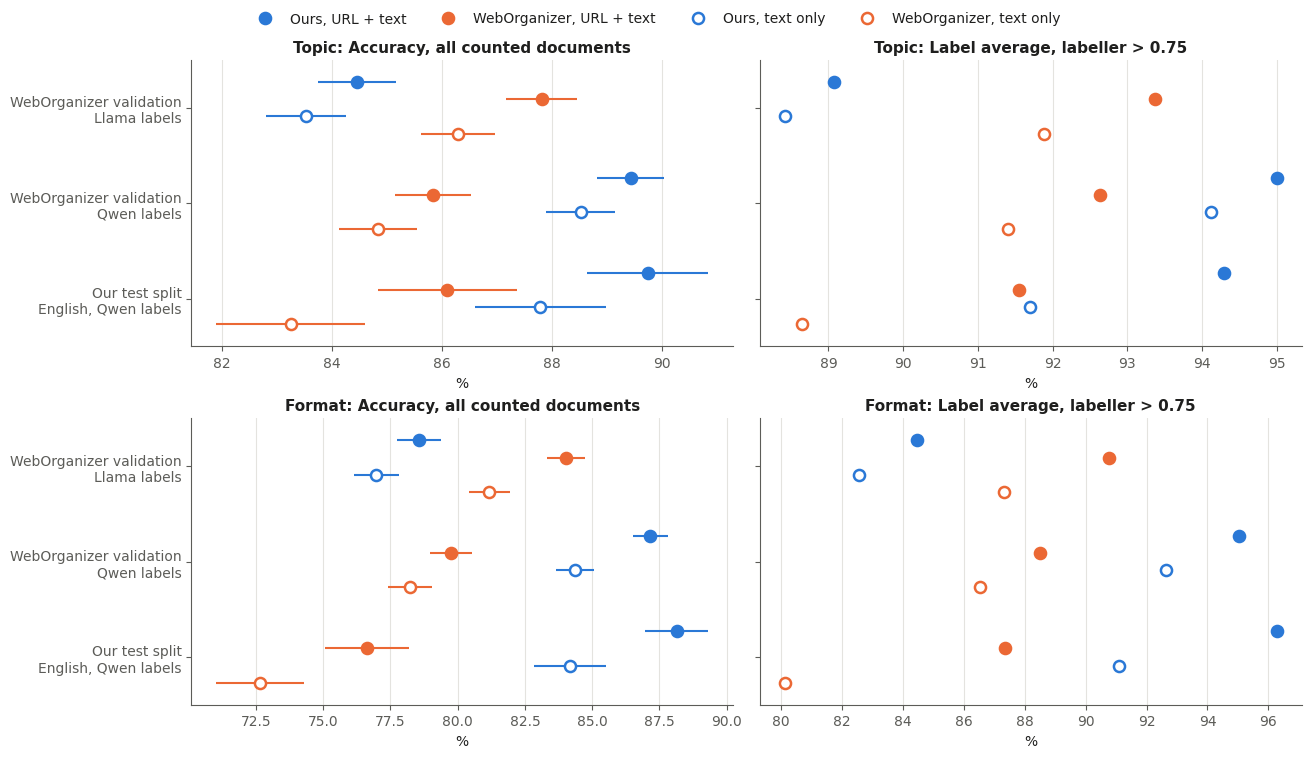

In [6]:
FIGURE_EVALUATIONS = [evaluation for evaluation in EVALUATIONS if "all languages" not in evaluation]
SERIES = [(system, input_name) for input_name in INPUTS for system in SYSTEMS]
OFFSETS = dict(zip(SERIES, np.linspace(-0.27, 0.27, len(SERIES))))
MEASURES = {"Accuracy": "Accuracy, all counted documents", "Label average, labeller > 0.75": "Label average, labeller > 0.75"}

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), layout="constrained", sharey=True)
for row, label_type in enumerate(LABEL_TYPES):
    for column, (measure, title) in enumerate(MEASURES.items()):
        ax = axes[row, column]
        for y, evaluation in enumerate(FIGURE_EVALUATIONS):
            for system, input_name in SERIES:
                result = SCORES[label_type, evaluation, system, input_name]
                ax.errorbar(100 * result[measure], y + OFFSETS[system, input_name],
                            xerr=100 * result["±"] if measure == "Accuracy" else None,
                            fmt="o", ms=8, elinewidth=1.5, capsize=0, **marker_style(system, input_name))
        ax.set_yticks(range(len(FIGURE_EVALUATIONS)), [evaluation.replace(", ", "\n", 1) for evaluation in FIGURE_EVALUATIONS])
        ax.set_ylim(len(FIGURE_EVALUATIONS) - 0.5, -0.5)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("%")
        ax.set_title(f"{label_type.capitalize()}: {title}")
handles = [Line2D([], [], marker="o", ms=8, linestyle="none", label=f"{system}, {'URL + text' if input_name == 'url' else 'text only'}",
                  **marker_style(system, input_name)) for system, input_name in SERIES]
fig.legend(handles=handles, loc="outside upper center", ncol=4)
plt.show()

### Ours minus WebOrganizer, paired

The difference in accuracy on the same documents (our classifier minus theirs with the same
input), with 95% intervals. Positive values favour our classifiers.

Label type,Evaluation,Input,Ours minus WebOrganizer (points),± (95%)
topic,"WebOrganizer validation, Llama labels",URL + text,-3.4,0.7
topic,"WebOrganizer validation, Llama labels",Text only,-2.8,0.7
topic,"WebOrganizer validation, Qwen labels",URL + text,+3.6,0.7
topic,"WebOrganizer validation, Qwen labels",Text only,+3.7,0.7
topic,"Our test split, English, Qwen labels",URL + text,+3.6,1.2
topic,"Our test split, English, Qwen labels",Text only,+4.5,1.3
topic,"Our test split, all languages, Qwen labels",URL + text,+35.5,0.2
topic,"Our test split, all languages, Qwen labels",Text only,+43.0,0.2
format,"WebOrganizer validation, Llama labels",URL + text,-5.5,0.8
format,"WebOrganizer validation, Llama labels",Text only,-4.2,0.8


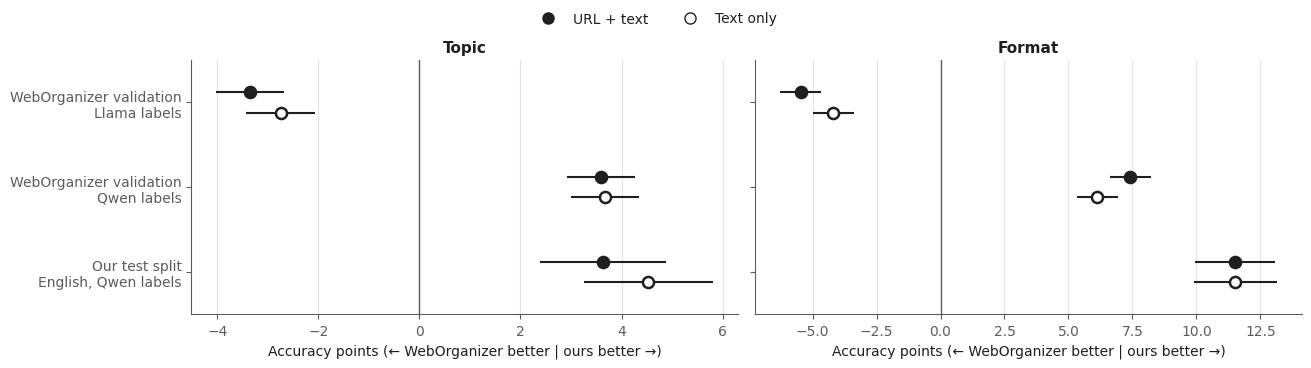

In [7]:
def paired_difference(a: dict, b: dict) -> tuple[float, float]:
    mask = a["_counted"]
    difference = a["_correct"][mask].astype(float) - b["_correct"][mask].astype(float)
    return difference.mean(), 1.96 * difference.std(ddof=1) / math.sqrt(len(difference))


rows = []
for label_type in LABEL_TYPES:
    for evaluation in EVALUATIONS:
        for input_name in INPUTS:
            gain, half = paired_difference(SCORES[label_type, evaluation, "Ours", input_name],
                                           SCORES[label_type, evaluation, "WebOrganizer", input_name])
            rows.append({"Label type": label_type, "Evaluation": evaluation, "Input": INPUT_NAMES[input_name],
                         "Ours minus WebOrganizer (points)": 100 * gain, "± (95%)": 100 * half})
DIFFERENCES = pd.DataFrame(rows)
display(DIFFERENCES.style.format({"Ours minus WebOrganizer (points)": "{:+.1f}", "± (95%)": "{:.1f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    for y, evaluation in enumerate(FIGURE_EVALUATIONS):
        for input_name, offset in zip(INPUTS, (-0.12, 0.12)):
            row = DIFFERENCES[(DIFFERENCES["Label type"] == label_type) & (DIFFERENCES["Evaluation"] == evaluation)
                              & (DIFFERENCES["Input"] == INPUT_NAMES[input_name])].iloc[0]
            ax.errorbar(row["Ours minus WebOrganizer (points)"], y + offset, xerr=row["± (95%)"], fmt="o", ms=8,
                        elinewidth=1.5, color=INK, markeredgecolor=INK, markeredgewidth=1.8,
                        markerfacecolor=INK if input_name == "url" else "white")
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(FIGURE_EVALUATIONS)), [evaluation.replace(", ", "\n", 1) for evaluation in FIGURE_EVALUATIONS])
    ax.set_ylim(len(FIGURE_EVALUATIONS) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Accuracy points (← WebOrganizer better | ours better →)")
    ax.set_title(label_type.capitalize())
fig.legend(handles=[Line2D([], [], marker="o", ms=8, linestyle="none", color=INK, markeredgecolor=INK,
                           markerfacecolor=INK if input_name == "url" else "white", label=INPUT_NAMES[input_name])
                    for input_name in INPUTS], loc="outside upper center", ncol=2)
plt.show()

**Reading sections 2 and 3:**
- **Each pair of classifiers wins on its own labeller's labels.** On the WebOrganizer pages,
  their URL models beat ours on Llama's labels (topic −3.4 ± 0.7, format −5.5 ± 0.8 points),
  and ours beat theirs on Qwen's labels for the same pages (+3.6 ± 0.7 and +7.4 ± 0.8). Most of
  the difference between the two systems is therefore the difference between their labellers
  (section 4), not between the classifiers.
- **Each system imitates its own labeller about equally well, ours slightly better.** On the same
  10,000 pages: ours against Qwen 89.4% (topic) and 87.2% (format) accuracy, 95.0% and 95.0%
  label average where Qwen > 0.75; theirs against Llama 87.8% and 84.0%, 93.4% and 90.8% where
  Llama > 0.75. Ours never trained on these English pages; theirs trained on the same
  distribution (their training split). Caveat: Qwen > 0.75 holds for fewer format pages (73.4%)
  than Llama > 0.75 (79.5%), which makes that subset somewhat easier for Qwen's side.
- **On the English pages of our test split** the gap in our favour is larger for format (+11.5
  ± 1.6 points) than on the WebOrganizer pages (+7.4 ± 0.8), which suggests that part of it comes
  from HPLT pages differing from WebOrganizer's (DCLM pool) pages; this isn't tested here.
- **Their models reproduce Table 7:** topic and both worst-label values match to 0.2 points;
  format label averages are 1.0–1.6 points lower than published, for unknown reasons.
- The URL helps both systems on every evaluation.

## 4. Where the two labellers disagree

On the 10,000 WebOrganizer validation pages. Qwen's top label is taken over all 26 labels, so
pages it calls *Other* or *Bad example* count as disagreement.

In [8]:
rows = []
for label_type in LABEL_TYPES:
    llama, qwen = WO[label_type]["targets"]["llama"], WO[label_type]["targets"]["qwen"]
    llama_top, qwen_top = llama.argmax(axis=1), qwen.argmax(axis=1)
    llama_sure, qwen_sure = llama.max(axis=1) > CONFIDENCE, qwen.max(axis=1) > CONFIDENCE
    same = llama_top == qwen_top
    rows.append({"Label type": label_type,
                 "Same top label": same.mean(),
                 "Same top label, Llama > 0.75": same[llama_sure].mean(),
                 "Same top label, Qwen > 0.75": same[qwen_sure].mean(),
                 "Same top label, both > 0.75": same[llama_sure & qwen_sure].mean(),
                 "Qwen top is Other or Bad example": (qwen_top >= 24).mean(),
                 "Share Llama > 0.75": llama_sure.mean(), "Share Qwen > 0.75": qwen_sure.mean()})
AGREEMENT = pd.DataFrame(rows).set_index("Label type")
display(AGREEMENT.style.format("{:.1%}"))

,Same top label,"Same top label, Llama > 0.75","Same top label, Qwen > 0.75","Same top label, both > 0.75",Qwen top is Other or Bad example,Share Llama > 0.75,Share Qwen > 0.75
Label type,,,,,,,
topic,86.1%,92.3%,92.6%,96.5%,1.6%,85.5%,83.7%
format,80.6%,88.7%,90.5%,95.6%,0.5%,79.5%,73.1%


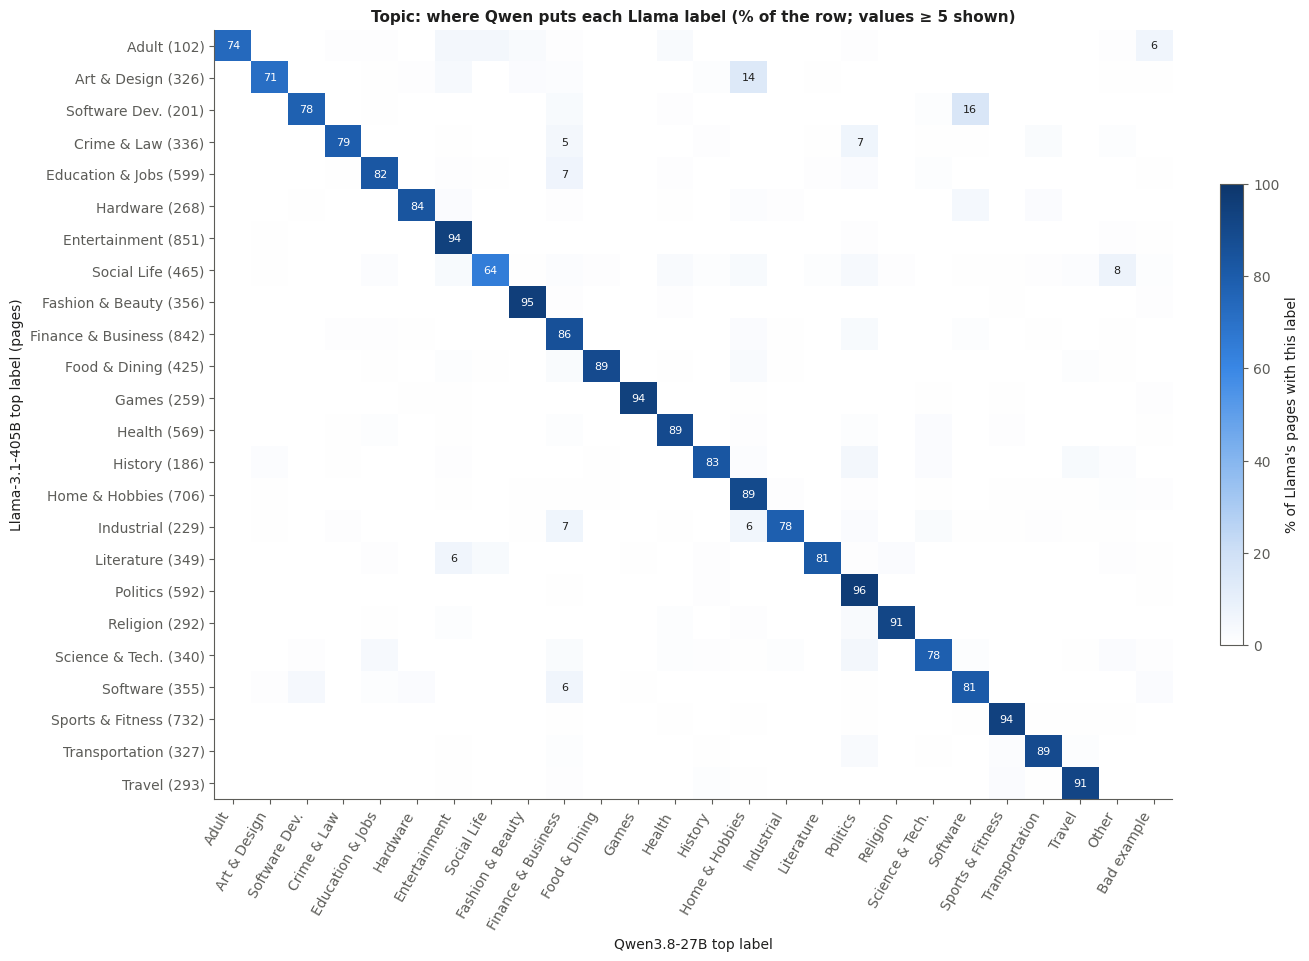

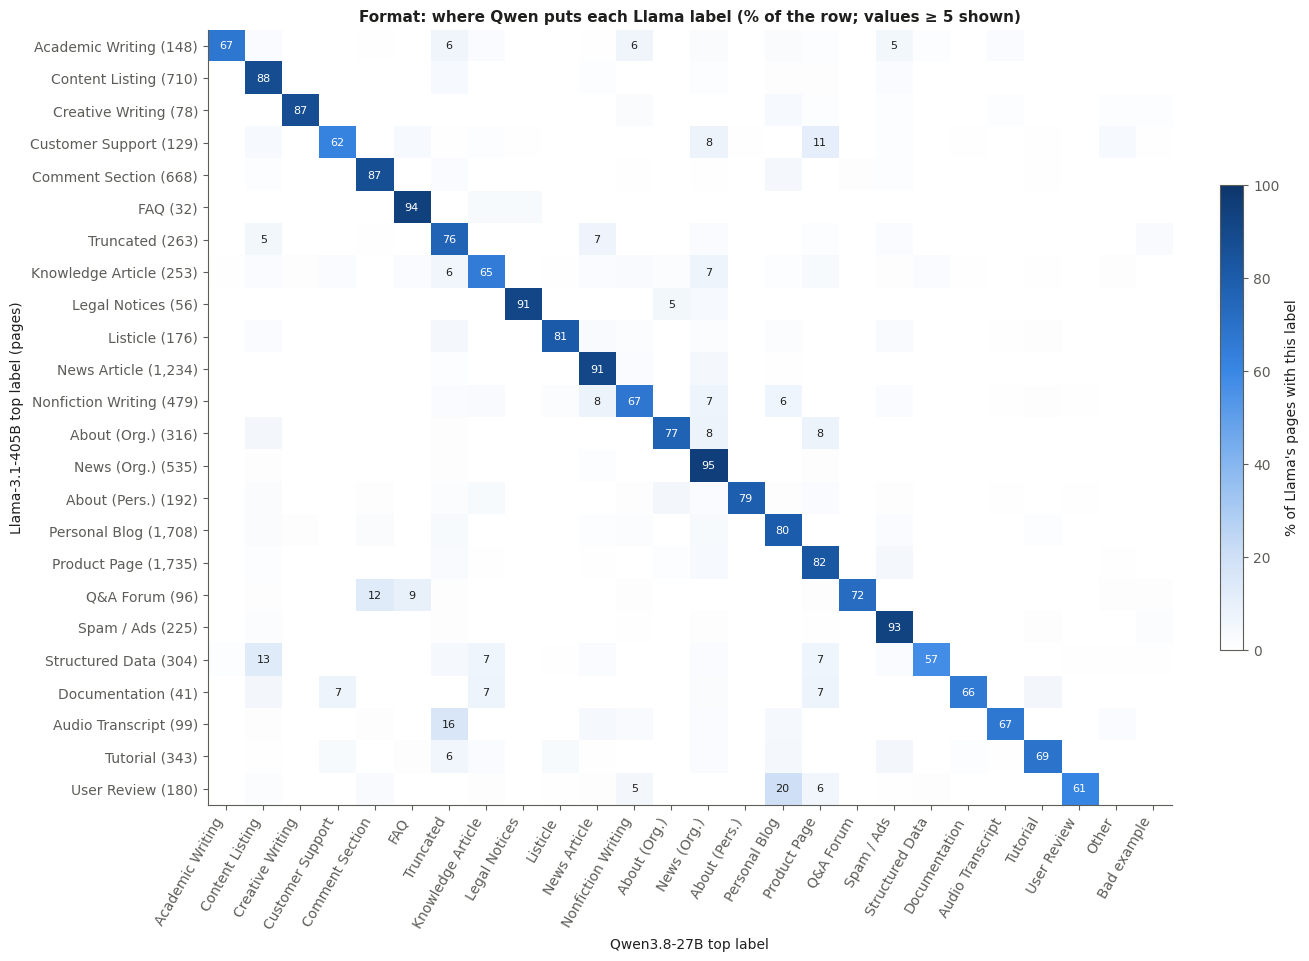

In [9]:
def agreement_matrix(label_type: str) -> pd.DataFrame:
    # Rows: Llama's top label; columns: Qwen's top label (all 26); values: share of the row's pages.
    names = LABELS[label_type]
    llama_top = WO[label_type]["targets"]["llama"].argmax(axis=1)
    qwen_top = WO[label_type]["targets"]["qwen"].argmax(axis=1)
    counts = pd.crosstab(pd.Categorical(llama_top, categories=range(24)), pd.Categorical(qwen_top, categories=range(len(names))),
                         dropna=False)
    counts.index = names[:24]
    counts.columns = names
    return counts


for label_type in LABEL_TYPES:
    counts = agreement_matrix(label_type)
    shares = counts.div(counts.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(13, 9.5), layout="constrained")
    image = ax.imshow(100 * shares.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
    for i in range(shares.shape[0]):
        for j in range(shares.shape[1]):
            value = 100 * shares.iat[i, j]
            if value >= 5:
                ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if value >= 50 else INK)
    ax.set_xticks(range(shares.shape[1]), shares.columns, rotation=60, ha="right")
    ax.set_yticks(range(shares.shape[0]), [f"{name} ({counts.iloc[i].sum():,})" for i, name in enumerate(shares.index)])
    ax.set_xlabel("Qwen3.8-27B top label")
    ax.set_ylabel("Llama-3.1-405B top label (pages)")
    ax.grid(False)
    ax.set_title(f"{label_type.capitalize()}: where Qwen puts each Llama label (% of the row; values ≥ 5 shown)")
    fig.colorbar(image, ax=ax, shrink=0.6, label="% of Llama's pages with this label")
    plt.show()

Per label: how often Qwen agrees with Llama's top label, on all pages and where Llama > 0.75,
and Qwen's most common other choice for that label. Sorted by agreement, lowest first.

In [10]:
def disagreement_table(label_type: str) -> pd.DataFrame:
    names = LABELS[label_type]
    llama, qwen = WO[label_type]["targets"]["llama"], WO[label_type]["targets"]["qwen"]
    llama_top, qwen_top = llama.argmax(axis=1), qwen.argmax(axis=1)
    sure = llama.max(axis=1) > CONFIDENCE
    rows = []
    for index, name in enumerate(names[:24]):
        mine = llama_top == index
        others = pd.Series(qwen_top[mine & (qwen_top != index)]).value_counts()
        rows.append({"Llama label": name, "Pages": int(mine.sum()),
                     "Qwen agrees": (qwen_top[mine] == index).mean(),
                     "Qwen agrees, Llama > 0.75": (qwen_top[mine & sure] == index).mean() if (mine & sure).any() else np.nan,
                     "Qwen's most common other label": names[others.index[0]] if len(others) else "—",
                     "Share of the label's pages": others.iloc[0] / mine.sum() if len(others) else 0.0,
                     "Qwen uses the label (pages)": int((qwen_top == index).sum())})
    return pd.DataFrame(rows).sort_values("Qwen agrees")


DISAGREEMENT = {}
for label_type in LABEL_TYPES:
    DISAGREEMENT[label_type] = disagreement_table(label_type)
    display(Markdown(f"**{label_type.capitalize()}**"))
    display(DISAGREEMENT[label_type].style.format(
        {"Pages": "{:,}", "Qwen agrees": "{:.1%}", "Qwen agrees, Llama > 0.75": "{:.1%}",
         "Share of the label's pages": "{:.1%}", "Qwen uses the label (pages)": "{:,}"}, na_rep="—").hide(axis="index"))

**Topic**

Llama label,Pages,Qwen agrees,"Qwen agrees, Llama > 0.75",Qwen's most common other label,Share of the label's pages,Qwen uses the label (pages)
Social Life,465,64.1%,73.1%,Other,7.5%,332
Art & Design,326,71.2%,83.6%,Home & Hobbies,14.1%,258
Adult,102,73.5%,79.3%,Bad example,5.9%,81
Software Dev.,201,77.6%,86.9%,Software,15.9%,181
Industrial,229,78.2%,89.0%,Finance & Business,6.6%,205
Science & Tech.,340,78.2%,85.9%,Politics,4.7%,314
Crime & Law,336,79.2%,87.7%,Politics,6.5%,295
Software,355,80.8%,91.3%,Finance & Business,5.9%,365
Literature,349,81.4%,89.4%,Entertainment,6.0%,310
Education & Jobs,599,82.3%,90.1%,Finance & Business,6.7%,550


**Format**

Llama label,Pages,Qwen agrees,"Qwen agrees, Llama > 0.75",Qwen's most common other label,Share of the label's pages,Qwen uses the label (pages)
Structured Data,304,57.2%,69.5%,Content Listing,12.8%,189
User Review,180,60.6%,71.6%,Personal Blog,20.0%,121
Customer Support,129,62.0%,74.7%,Product Page,10.9%,104
Knowledge Article,253,64.8%,80.2%,News (Org.),7.1%,235
Documentation,41,65.9%,85.2%,Product Page,7.3%,35
Audio Transcript,99,66.7%,76.0%,Truncated,16.2%,88
Academic Writing,148,66.9%,80.7%,Truncated,6.1%,104
Nonfiction Writing,479,67.4%,82.9%,News Article,7.5%,429
Tutorial,343,68.5%,78.9%,Truncated,5.5%,276
Q&A Forum,96,71.9%,83.5%,Comment Section,12.5%,78


**Reading section 4:**
- The labellers give the same top label on 86.1% (topic) and 80.6% (format) of the pages, and on
  96.5% and 95.6% of the pages where both are above 0.75. Disagreement is concentrated on pages
  where at least one labeller is unsure.
- **Topic:** Qwen agrees least with Llama's *Social Life* (64%; 7.5% become *Other*), *Art &
  Design* (71%; 14% become *Home & Hobbies*), *Adult* (74%) and *Software Dev.* (78%; 16%
  become *Software*).
- **Format:** *Structured Data* (57%; 13% become *Content Listing*), *User Review* (61%; 20% become
  *Personal Blog*), *Customer Support* (62%; 11% become *Product Page*), *Knowledge Article* (65%)
  and *Audio Transcript* (67%; 16% become *Truncated*).
- **Some labels are used much more by one labeller:** Qwen gives *Truncated* to 467 pages (Llama
  263), *Spam / Ads* to 409 (225) and *News (Org.)* to 819 (535); it gives *Structured Data* to 189
  (304), *User Review* to 121 (180) and *Social Life* to 332 (465).

## 5. Per-label accuracy: own labeller and the other labeller

URL + text classifiers on the WebOrganizer validation pages. For each label: accuracy on the
pages whose labeller gives that label > 0.75, against the classifier's own labeller (filled) and
the other labeller (hollow). Grey bars: how often Qwen agrees with Llama on that label's pages
where Llama > 0.75, roughly the ceiling for scoring a classifier against the other labeller.
Labels are sorted by that agreement.

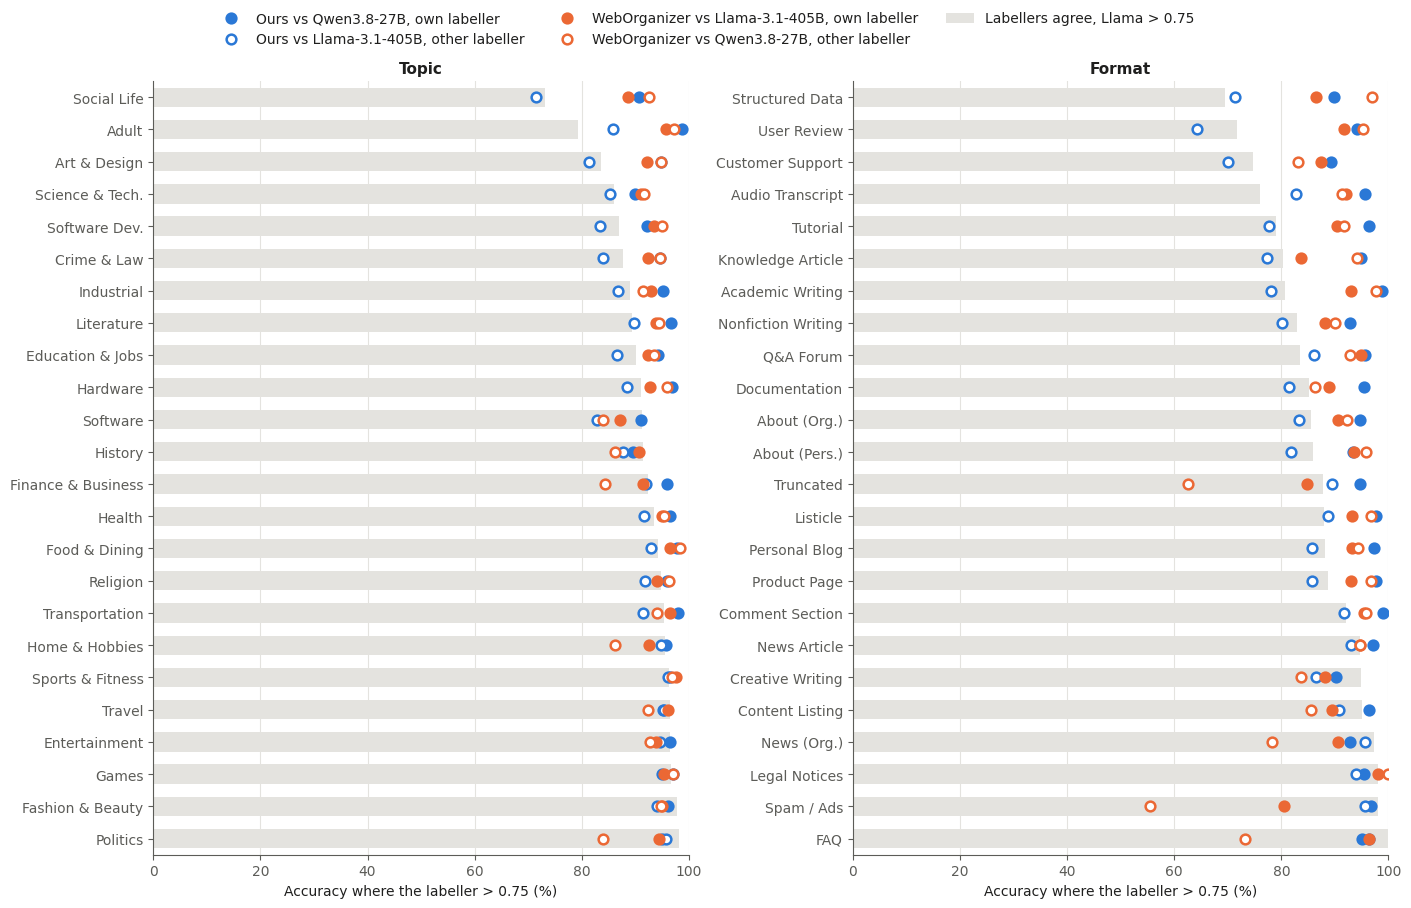

**Topic**

,Ours vs Llama-3.1-405B (other),Ours vs Qwen3.8-27B (own),WebOrganizer vs Llama-3.1-405B (own),WebOrganizer vs Qwen3.8-27B (other),"Labellers agree, Llama > 0.75"
Social Life,71.5%,90.7%,88.5%,92.5%,73.1%
Adult,85.9%,98.6%,95.7%,97.3%,79.3%
Art & Design,81.2%,94.7%,92.2%,94.7%,83.6%
Science & Tech.,85.2%,90.0%,91.1%,91.7%,85.9%
Software Dev.,83.3%,92.1%,93.5%,95.0%,86.9%
Crime & Law,83.9%,94.5%,92.3%,94.5%,87.7%
Industrial,86.7%,95.1%,92.8%,91.5%,89.0%
Literature,89.7%,96.7%,93.8%,94.4%,89.4%
Education & Jobs,86.6%,94.2%,92.4%,93.5%,90.1%
Hardware,88.4%,96.9%,92.7%,95.9%,90.9%


**Format**

,Ours vs Llama-3.1-405B (other),Ours vs Qwen3.8-27B (own),WebOrganizer vs Llama-3.1-405B (own),WebOrganizer vs Qwen3.8-27B (other),"Labellers agree, Llama > 0.75"
Structured Data,71.3%,89.8%,86.5%,96.9%,69.5%
User Review,64.2%,94.0%,91.8%,95.2%,71.6%
Customer Support,70.1%,89.2%,87.4%,83.1%,74.7%
Audio Transcript,82.7%,95.7%,92.0%,91.3%,76.0%
Tutorial,77.8%,96.4%,90.4%,91.7%,78.9%
Knowledge Article,77.3%,94.8%,83.7%,94.1%,80.2%
Academic Writing,78.1%,98.9%,93.0%,97.8%,80.7%
Nonfiction Writing,80.1%,92.7%,88.1%,90.0%,82.9%
Q&A Forum,86.1%,95.7%,94.9%,92.8%,83.5%
Documentation,81.5%,95.5%,88.9%,86.4%,85.2%


In [11]:
PER_LABEL = {}
for label_type in LABEL_TYPES:
    columns = {}
    for system in SYSTEMS:
        for labeller in LABELLERS:
            evaluation = f"WebOrganizer validation, {'Llama' if labeller == 'llama' else 'Qwen'} labels"
            result = SCORES[label_type, evaluation, system, "url"]
            kind = "own" if OWN_LABELLER[system] == labeller else "other"
            columns[f"{system} vs {LABELLERS[labeller]} ({kind})"] = result["_per_label_sure"]
    table = pd.DataFrame(columns)
    table.index = [LABELS[label_type][index] for index in table.index]
    disagreement = DISAGREEMENT[label_type].set_index("Llama label")
    table["Labellers agree, Llama > 0.75"] = disagreement.loc[table.index, "Qwen agrees, Llama > 0.75"]
    PER_LABEL[label_type] = table.sort_values("Labellers agree, Llama > 0.75")

fig, axes = plt.subplots(1, 2, figsize=(14, 9), layout="constrained")
for ax, label_type in zip(axes, LABEL_TYPES):
    table = PER_LABEL[label_type]
    y = np.arange(len(table))
    ax.barh(y, 100 * table["Labellers agree, Llama > 0.75"], height=0.6, color=GRID, edgecolor="none",
            label="Labellers agree, Llama > 0.75")
    for system in SYSTEMS:
        for kind in ("own", "other"):
            column = next(c for c in table.columns if c.startswith(system) and f"({kind})" in c)
            ax.plot(100 * table[column], y, "o", ms=7, linestyle="none", label=column,
                    **marker_style(system, "url" if kind == "own" else "nourl"))
    ax.set_yticks(y, table.index)
    ax.set_ylim(len(table) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Accuracy where the labeller > 0.75 (%)")
    ax.set_title(f"{label_type.capitalize()}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, [label.replace(" (own)", ", own labeller").replace(" (other)", ", other labeller") for label in labels],
           loc="outside upper center", ncol=3)
plt.show()

for label_type in LABEL_TYPES:
    display(Markdown(f"**{label_type.capitalize()}**"))
    display(PER_LABEL[label_type].style.format("{:.1%}"))

**Reading section 5:**
- **Our classifiers' errors against Llama sit where the labellers disagree.** Per label, our
  accuracy against Llama tracks how often Qwen agrees with Llama (grey bars): *Social Life* 71.5%
  against 73.1% agreement, *Structured Data* 71.3% against 69.5%, *User Review* 64.2% against
  71.6%. Against Qwen, the same labels score 90.7%, 89.8% and 94.0%.
- **Their weakest labels against Qwen are labels Qwen uses more often than Llama:** *Spam / Ads*
  55.5%, *Truncated* 62.6%, *FAQ* 73.2% and *News (Org.)* 78.2% for format; *Software* 83.9%,
  *Politics* 84.0% and *Finance & Business* 84.4% for topic. Their classifiers, trained on
  Llama's narrower use of these labels, miss the extra pages Qwen gives them.
- Against its own labeller, our worst label is *History* (89.5%, topic) and *Customer Support*
  (89.2%, format); theirs is *Software* (87.1%) and *Spam / Ads* (80.5%).

## 6. Our test split: by quality bucket and language

All 128 languages, Qwen labels, duplicates of training left out. WebOrganizer's classifiers are
built on an English-only encoder, so this mostly shows how far each language is from English;
it is not a fair test of them outside English.

In [12]:
rows = {}
for label_type in LABEL_TYPES:
    data = HPLT[label_type]
    targets = data["targets"]["qwen"]
    for source in SOURCES:
        mask = data["keep"] & (data["docs"]["source"] == source).to_numpy()
        for system in SYSTEMS:
            for input_name in INPUTS:
                result = score(data["predictions"][system, input_name][0], targets, mask)
                rows[label_type, source, system, INPUT_NAMES[input_name]] = {
                    key: result[key] for key in ("Documents", "Accuracy", "Label average", "Share labeller > 0.75",
                                                 "Accuracy, labeller > 0.75", "Label average, labeller > 0.75")}
by_source = pd.DataFrame.from_dict(rows, orient="index")
by_source.index.names = ["Label type", "Source", "Classifier", "Input"]
show_scores(by_source, ["Accuracy", "Label average", "Accuracy, labeller > 0.75", "Label average, labeller > 0.75"],
            level=["Label type", "Source"])

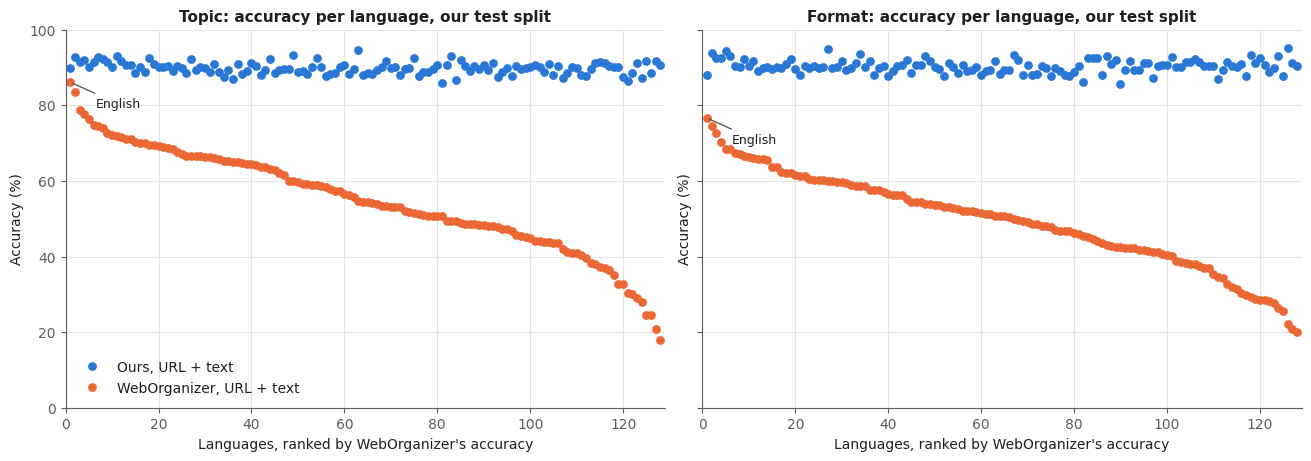

**Topic**: the 10 languages where WebOrganizer's URL model is most accurate

,Documents,"Ours, URL + text","Ours, Text only","WebOrganizer, URL + text","WebOrganizer, Text only"
English,"2,914",89.7%,87.8%,86.1%,83.3%
Pangasinan,"1,339",92.8%,89.5%,83.4%,66.2%
Xhosa,"2,845",91.5%,88.5%,78.8%,64.8%
Maltese,"2,924",91.9%,89.7%,77.8%,70.1%
Filipino,"2,892",90.2%,87.7%,76.2%,72.0%
Cebuano,"2,893",91.5%,88.7%,74.9%,68.1%
Tok Pisin,"1,481",92.8%,85.6%,74.5%,56.9%
Occitan,"2,944",92.3%,90.2%,74.0%,51.2%
Asturian,"2,925",91.3%,89.5%,72.6%,69.9%
Italian,"2,928",90.1%,86.9%,72.2%,66.5%


**Topic**: the 10 languages where WebOrganizer's URL model is least accurate

,Documents,"Ours, URL + text","Ours, Text only","WebOrganizer, URL + text","WebOrganizer, Text only"
Maithili,"2,749",90.2%,87.9%,32.6%,24.5%
Korean,"2,896",87.6%,86.6%,32.6%,25.4%
Bashkir,"2,829",86.3%,83.8%,30.3%,22.1%
Kyrgyz,"2,875",88.6%,86.5%,30.1%,18.9%
Sindhi,"2,844",91.2%,88.6%,29.1%,17.8%
Tatar,"2,821",87.1%,83.9%,28.0%,18.0%
Nepali,"2,953",91.8%,90.8%,24.6%,9.1%
Persian,"2,865",88.6%,86.4%,24.6%,15.4%
Pashto,"2,932",91.7%,89.8%,20.7%,11.2%
Central Kurdish,"2,951",90.5%,90.0%,17.8%,9.3%


**Format**: the 10 languages where WebOrganizer's URL model is most accurate

,Documents,"Ours, URL + text","Ours, Text only","WebOrganizer, URL + text","WebOrganizer, Text only"
English,"2,866",88.1%,84.2%,76.6%,72.6%
Waray,"1,467",93.9%,92.8%,74.5%,41.6%
Ilocano,"2,628",92.6%,91.1%,72.8%,56.6%
Lombard,"2,850",92.5%,90.4%,70.4%,49.6%
Ligurian,"1,764",94.3%,91.1%,68.5%,55.3%
Esperanto,"2,770",93.1%,91.3%,68.5%,51.5%
Balinese,"2,046",90.5%,88.3%,67.4%,53.4%
Sicilian,"2,253",90.2%,88.2%,67.1%,51.3%
Cebuano,"2,616",92.1%,88.6%,66.6%,52.6%
Filipino,"2,778",90.4%,87.6%,66.5%,54.9%


**Format**: the 10 languages where WebOrganizer's URL model is least accurate

,Documents,"Ours, URL + text","Ours, Text only","WebOrganizer, URL + text","WebOrganizer, Text only"
Lao,"2,906",91.3%,87.9%,28.9%,15.2%
Malayalam,"2,877",92.4%,89.5%,28.6%,12.3%
Urdu,"2,861",90.7%,88.9%,28.6%,14.0%
Amharic,"2,675",88.7%,84.9%,28.3%,16.2%
Bengali,"2,837",89.7%,87.4%,27.8%,15.4%
Assamese,"2,708",93.1%,90.6%,26.3%,13.3%
Burmese,"2,781",87.7%,84.7%,25.6%,15.8%
Odia,"2,916",95.1%,93.8%,22.3%,10.5%
Central Kurdish,"2,924",91.2%,89.4%,20.9%,10.4%
Pashto,"2,836",90.4%,88.6%,19.9%,16.1%


In [13]:
def per_language_accuracy(label_type: str) -> pd.DataFrame:
    data = HPLT[label_type]
    top = data["targets"]["qwen"].argmax(axis=1)
    counted = data["keep"] & (top < 24)
    frame = pd.DataFrame({"language": data["docs"]["language"].to_numpy()[counted]})
    for system in SYSTEMS:
        for input_name in INPUTS:
            frame[f"{system}, {INPUT_NAMES[input_name]}"] = data["predictions"][system, input_name][0][counted] == top[counted]
    table = frame.groupby("language").mean()
    table.insert(0, "Documents", frame.groupby("language").size())
    table.index = [LANGUAGE_NAMES.get(language, language) for language in table.index]
    return table


PER_LANGUAGE = {label_type: per_language_accuracy(label_type) for label_type in LABEL_TYPES}

# Languages ranked by the WebOrganizer URL model's accuracy; both URL models' accuracy per language.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained", sharey=True)
for ax, label_type in zip(axes, LABEL_TYPES):
    table = 100 * PER_LANGUAGE[label_type].sort_values("WebOrganizer, URL + text", ascending=False)
    rank = np.arange(1, len(table) + 1)
    for system in SYSTEMS:
        ax.plot(rank, table[f"{system}, URL + text"], "o", ms=4.5, linestyle="none", label=f"{system}, URL + text",
                **marker_style(system, "url"))
    english = table.index.get_loc("English") + 1
    ax.annotate("English", (english, table.loc["English", "WebOrganizer, URL + text"]), xytext=(18, -18),
                textcoords="offset points", fontsize=9, color=INK, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1})
    ax.set_xlim(0, len(table) + 1)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Languages, ranked by WebOrganizer's accuracy")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"{label_type.capitalize()}: accuracy per language, our test split")
axes[0].legend(loc="lower left")
plt.show()

for label_type in LABEL_TYPES:
    ranked = PER_LANGUAGE[label_type].sort_values("WebOrganizer, URL + text", ascending=False)
    for title, table in (("most", ranked.head(10)), ("least", ranked.tail(10))):
        display(Markdown(f"**{label_type.capitalize()}**: the 10 languages where WebOrganizer's URL model is {title} accurate"))
        display(table.style.format({column: "{:.1%}" for column in table.columns if column != "Documents"} | {"Documents": "{:,}"}))

**Reading section 6:** WebOrganizer's classifiers drop to 54.4% (topic) and 48.8% (format) over
all languages, as expected from an English encoder; the languages where they do best are, after
English, mostly Latin-script languages with much English vocabulary or code-switching on the web
(e.g. Filipino, Cebuano, Tok Pisin, Maltese), and the worst are languages in non-Latin scripts
(e.g. Pashto, Central Kurdish, Odia, Nepali, at 18–25%). Our URL models stay between about 85%
and 95% in every language. Their accuracy is highest on the *poor* bucket, perhaps because poor pages carry more
English boilerplate; that isn't checked here. Our URL models are nearly as accurate on poor pages
as on clean ones (topic 88.2% against 91.0%), while our text-only models lose more there (80.7%
against 90.0%).

## 7. How often our models choose *Other* or *Bad example*

Our classifiers have two labels that WebOrganizer's labels lack. The scores above drop them
before taking the top label; this shows how often they would otherwise have been the top
label, on WebOrganizer's pages and on our test split.

In [14]:
rows = []
for label_type in LABEL_TYPES:
    for name, data in (("WebOrganizer validation", WO[label_type]), ("Our test split", HPLT[label_type])):
        keep = data.get("keep", np.ones(len(data["docs"]), dtype=bool))
        for input_name in INPUTS:
            full_top = data["predictions"]["Ours", input_name][1][keep]
            row = {"Label type": label_type, "Evaluation set": name, "Input": INPUT_NAMES[input_name]}
            for index in (24, 25):
                row[f"Ours: {LABELS[label_type][index]}"] = (full_top == index).mean()
            if "qwen" in data["targets"]:
                qwen_top = data["targets"]["qwen"].argmax(axis=1)[keep]
                for index in (24, 25):
                    row[f"Qwen: {LABELS[label_type][index]}"] = (qwen_top == index).mean()
            rows.append(row)
display(pd.DataFrame(rows).style.format({column: "{:.1%}" for column in pd.DataFrame(rows).columns if ":" in column})
        .hide(axis="index"))

Label type,Evaluation set,Input,Ours: Other,Ours: Bad example,Qwen: Other,Qwen: Bad example
topic,WebOrganizer validation,URL + text,0.6%,0.7%,0.9%,0.6%
topic,WebOrganizer validation,Text only,0.7%,0.7%,0.9%,0.6%
topic,Our test split,URL + text,0.6%,3.0%,0.8%,2.7%
topic,Our test split,Text only,0.6%,3.5%,0.8%,2.7%
format,WebOrganizer validation,URL + text,0.2%,0.2%,0.3%,0.2%
format,WebOrganizer validation,Text only,0.1%,0.2%,0.3%,0.2%
format,Our test split,URL + text,0.5%,6.5%,0.5%,6.3%
format,Our test split,Text only,0.5%,6.9%,0.5%,6.3%


**Reading section 7:** our classifiers choose *Other* and *Bad example* about as often as Qwen
does (e.g. format *Bad example* 6.5% against Qwen's 6.3% on our test split). On the WebOrganizer
pages both are rare (≤ 0.9% each), so dropping them before the argmax affects few pages.

## 8. Summary

1. **On the same English pages, each pair of classifiers agrees best with the labeller it was
   trained on.** Theirs beat ours on Llama-3.1-405B's labels (URL models: topic −3.4, format −5.5
   accuracy points); ours beat theirs on Qwen3.8-27B's labels (+3.6 and +7.4). The labellers
   themselves give the same top label on 86% (topic) and 81% (format) of these pages, enough to
   explain the gap.
2. **Our classifiers imitate Qwen at least as well as theirs imitate Llama**, on pages from their
   own distribution that ours never saw: 89.4% and 87.2% accuracy against 87.8% and 84.0%; label
   average where the labeller > 0.75: 95.0% and 95.0% against 93.4% and 90.8% (Table 7's measure).
3. **Where they disagree, the labellers draw label boundaries differently, not randomly:** Qwen
   uses *Truncated*, *Spam / Ads* and *News (Org.)* much more often than Llama, and *Structured
   Data*, *User Review* and *Social Life* less. Our classifiers' per-label errors against Llama
   follow these disagreements closely.
4. **On our test split** ours are ahead on English (+3.6 topic, +11.5 format) and, as expected
   for an English-only model, far ahead elsewhere (WebOrganizer 54.4% and 48.8% over 128
   languages).
5. **Which labeller is closer to human judgement can't be decided from these numbers.** That needs
   human labels on pages like these, ideally on the pages where Qwen and Llama disagree
   (section 4 lists them by label).
6. Their published Table 7 is reproduced (topic within 0.2 points; format label averages 1.0–1.6
   points lower, worst labels identical), so the cross-evaluation setup is sound.